In [12]:
import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [13]:
# Generating the star-embryo system

M_A = 1.0788 | units.Msun
M_embryo = 0.0123 | units.Mearth
a_embryo = 2 | units.au
e_embryo = 0

stars, planets = generate_binaries(M_A, M_embryo, a_embryo, e_embryo, G=constants.G)

star = stars[0]
planet = planets[0]

planet.position -= star.position
planet.velocity -= star.velocity

R_acc = 0.1 | units.au
planet.radius = R_acc

star.name = "Alpha_Centauri_A"
planet.name = "Alpha_Centauri_Ab"

system = Particles()
system.add_particle(star)
system.add_particle(planet)
system.move_to_center()

print(system)

                 key         mass         name       radius           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
13239219802568344182    1.079e+00  Alpha_Centauri_A    0.000e+00    0.000e+00   -2.054e-13   -0.000e+00   -6.847e-08   -0.000e+00   -0.000e+00
12595839404355710069    3.693e-08  Alpha_Centauri_Ab    1.000e-01    0.000e+00    6.000e-06    0.000e+00    2.000e+00    0.000e+00    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========


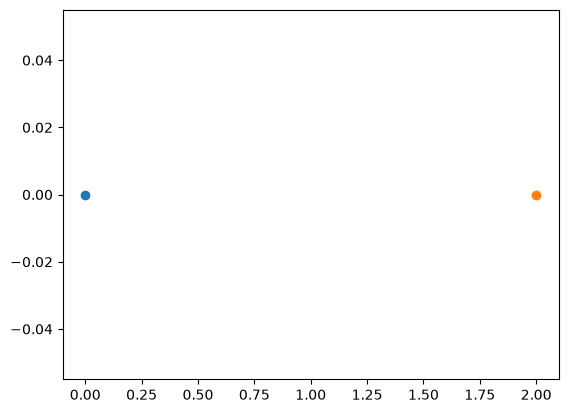

In [14]:
import matplotlib.pyplot as plt
plt.scatter(star.x.value_in(units.au), star.y.value_in(units.au))
plt.scatter(planet.x.value_in(units.au), planet.y.value_in(units.au))

In [15]:
from amuse.ext.protodisk import ProtoPlanetaryDisk

M_scale = system.mass.sum()
R_scale = a_embryo
converter = nbody_system.nbody_to_si(M_scale, R_scale)
Ndisk = 1000
Rin = 0.2 | units.au
Rout = 3 | units.au
rmin = Rin/R_scale
rmax = Rout/R_scale
Mdisk = 0.001 | units.Msun
disk = ProtoPlanetaryDisk(Ndisk,
                          convert_nbody=converter,
                          radius_min=rmin, # inner radius in units of reference length
                          radius_max=rmax, # outer radius in units of reference length
                          q_out=10, # Toomre Q parameter
                          discfraction=Mdisk/M_A).result
disk.name = "disk"
system.move_to_center()
disk.move_to_center()
print(disk.position.lengths().max().in_(units.au))
disk.position += star.position # absolute coordinates of disk 
disk.velocity += star.velocity # absolute velocity of disk
masses = Mdisk / float(Ndisk) # mass distributed equally 
disk.mass = masses
rho = 3.0 | (units.g / units.cm**3) # assume density of material
disk.radius = (disk.mass / (4 * rho))**(1./3.) # assign physical radius to each particle using formula
system.add_particles(disk)

print(system[system.name == "disk"])


3.06006464967 au
                 key         mass         name       radius            u           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  m**2 * s**-2  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
15883392125188262672    1.000e-06         disk    3.672e-05    9.266e+03    5.729e-06   -8.884e-07    0.000e+00   -3.202e-01   -2.206e+00    6.075e-03
10692291875279265877    1.000e-06         disk    3.672e-05    8.826e+03   -4.638e-06    2.865e-06    0.000e+00    1.256e+00    1.942e+00   -1.038e-02
16954956892448587977    1.000e-06         disk    3.672e-05    8.391e+03    5.072e-06   -1.399e-06    0.000e+00   -6.821e-01   -2.617e+00    3.2

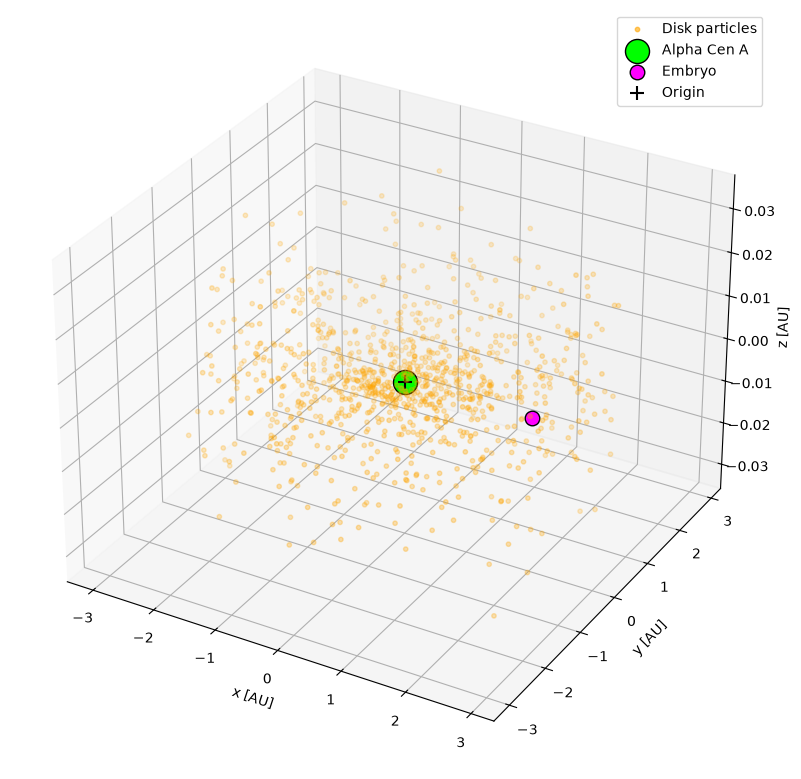

In [16]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           disk.z.value_in(units.au),
           s=10, c="orange", alpha=0.6, label="Disk particles")

ax.scatter(star.x.value_in(units.au),
           star.y.value_in(units.au),
           star.z.value_in(units.au),
           s=300, c="lime", edgecolors="black",
           depthshade=False, label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           planet.z.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
           depthshade=False, label="Embryo")

ax.scatter(0, 0, 0, color="black", marker="+", s=100, label="Origin")
#ax.set_xlim(-20, 20)
#ax.set_ylim(-20, 20)
#ax.set_zlim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
# Have to find a method to define accretion by the embryo

import argparse
from amuse.datamodel import Particles
from amuse.units import units, nbody_system
from amuse.ic.gasplummer import new_plummer_gas_model


def accrete_particles(sinks, gas):
    removed_particles = Particles() # empty particle set for removed particles
    for s in sinks:
        xs, ys, zs = s.x, s.y, s.z # position of embryo
        radius_squared = s.radius**2 # accretion radius of embryo
        insink = gas.select_array( # True if gas particle is within accretion radius
            lambda x, y, z: (x - xs) ** 2 + (y - ys) ** 2 + (z - zs) ** 2
            < radius_squared,
            ["x", "y", "z"],
        )
        if len(insink) == 0:
            continue

        cm = s.position * s.mass # mass-weighted position and velocity 
        p = s.velocity * s.mass
        s.mass += insink.total_mass() # add mass of accreted gas particles
        s.position = (cm + insink.center_of_mass() * insink.total_mass()) / s.mass
        s.velocity = (p + insink.total_momentum()) / s.mass # conservation of momentum
        removed_particles.add_particles(insink)
    return removed_particles



In [18]:
from amuse.community.huayno.interface import Huayno

gravity = Huayno(converter)
gravity.particles.add_particles(system)
channel = gravity.particles.new_channel_to(system)

In [19]:
def evolve_gravity(gravity, system, channel, t_end):
    channel_to_gravity = system.new_channel_to(gravity.particles)
    model_time = 0 | units.yr
    dt = 0.01 | units.yr
    time_saved = []
    xA, yA, zA = [], [], []
    xP, yP, zP = [], [], []
    xD, yD, zD = [], [], []
    mass_embryo = []
    while model_time < t_end:
        model_time += dt
        if model_time > t_end:
            model_time = t_end
        gravity.evolve_model(model_time)
        channel.copy() # copy state from gravity code to framework particles
        planet = system[system.name == "Alpha_Centauri_Ab"]
        disk = system[system.name == "disk"]
        accreted = accrete_particles(planet, disk)
        if len(accreted) > 0:
            print(f"Accretion of {len(accreted)} particles has happened!")
            old_mass = planet.mass.copy()
            system.remove_particles(accreted)
            gravity.particles.remove_particles(accreted)
            channel_to_gravity.copy_attributes(["mass", "x", "y", "z", "vx", "vy", "vz"]) # copy updated sink properties back to gravity code
            print(
                "Embryo mass:",
                old_mass.in_(units.Mearth),
                "->",
                planet.mass.in_(units.Mearth)
            )
            channel = gravity.particles.new_channel_to(system) # rebuild channels after particle removal
            channel_to_gravity = system.new_channel_to(gravity.particles)

        star = system[system.name == "Alpha_Centauri_A"]
        planet = system[system.name == "Alpha_Centauri_Ab"]
        disk = system[system.name == "disk"]

        time_saved.append(model_time.value_in(units.yr))

        xA.append(star.x.value_in(units.au)[0])
        yA.append(star.y.value_in(units.au)[0])
        zA.append(star.z.value_in(units.au)[0])

        xP.append(planet.x.value_in(units.au)[0])
        yP.append(planet.y.value_in(units.au)[0])
        zP.append(planet.z.value_in(units.au)[0])

        xD.append(disk.x.value_in(units.au))
        yD.append(disk.y.value_in(units.au))
        zD.append(disk.z.value_in(units.au))

        mass_embryo.append(planet.mass.value_in(units.Mearth)[0])

        print(f"Model time = {model_time.in_(units.yr)}, "
            f"Mplanet = {planet.mass.in_(units.Mearth)}")

    return (time_saved, xA, yA, zA, xP, yP, zP, xD, yD, zD, mass_embryo,)

In [20]:
results = evolve_gravity(gravity, system, channel, 5 | units.yr)

Model time = 0.01 yr, Mplanet = [0.0123] MEarth
Model time = 0.02 yr, Mplanet = [0.0123] MEarth
Model time = 0.03 yr, Mplanet = [0.0123] MEarth
Model time = 0.04 yr, Mplanet = [0.0123] MEarth
Model time = 0.05 yr, Mplanet = [0.0123] MEarth
Model time = 0.060000000000000005 yr, Mplanet = [0.0123] MEarth
Model time = 0.07 yr, Mplanet = [0.0123] MEarth
Model time = 0.08 yr, Mplanet = [0.0123] MEarth
Model time = 0.09 yr, Mplanet = [0.0123] MEarth
Model time = 0.09999999999999999 yr, Mplanet = [0.0123] MEarth
Model time = 0.10999999999999999 yr, Mplanet = [0.0123] MEarth
Model time = 0.11999999999999998 yr, Mplanet = [0.0123] MEarth
Model time = 0.12999999999999998 yr, Mplanet = [0.0123] MEarth
Model time = 0.13999999999999999 yr, Mplanet = [0.0123] MEarth
Model time = 0.15 yr, Mplanet = [0.0123] MEarth
Model time = 0.16 yr, Mplanet = [0.0123] MEarth
Model time = 0.17 yr, Mplanet = [0.0123] MEarth
Model time = 0.18000000000000002 yr, Mplanet = [0.0123] MEarth
Model time = 0.190000000000000


Saving video...
Rendering frame 501/501 (100.0%)Done.
Rendering frame 1/501 (0.2%)

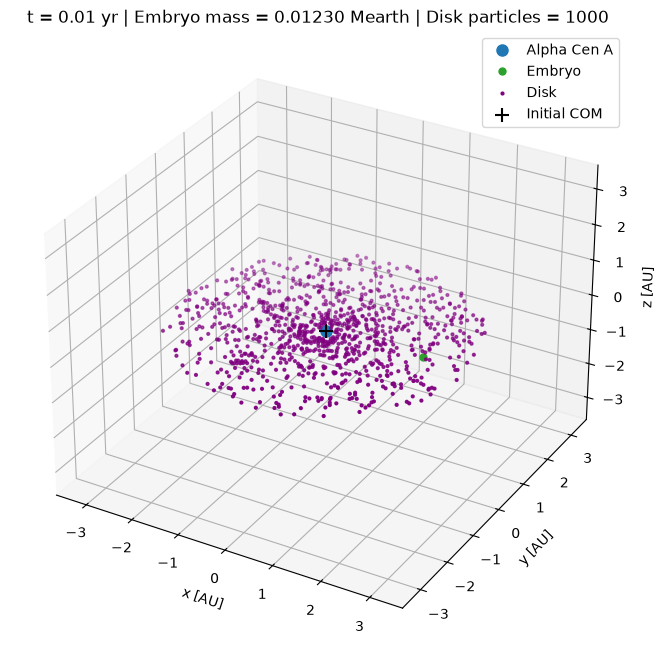

In [21]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.pyplot as plt
import numpy as np

color_A = "tab:blue"
color_P = "tab:green"
color_D = "purple"

time_saved, xA, yA, zA, xP, yP, zP, xD, yD, zD, mass_embryo = results

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

# Determine plot limits using all saved positions
all_x = np.concatenate([np.asarray(xA), np.asarray(xP)] +
                       [np.asarray(x) for x in xD if len(x) > 0])
all_y = np.concatenate([np.asarray(yA), np.asarray(yP)] +
                       [np.asarray(y) for y in yD if len(y) > 0])
all_z = np.concatenate([np.asarray(zA), np.asarray(zP)] +
                       [np.asarray(z) for z in zD if len(z) > 0])

extent = max(
    np.max(np.abs(all_x)),
    np.max(np.abs(all_y)),
    np.max(np.abs(all_z))
) * 1.1

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.set_zlim(-extent, extent)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")

# Particles
starA, = ax.plot([], [], [], "o", ms=8, color=color_A, label="Alpha Cen A")
planet, = ax.plot([], [], [], "o", ms=5, color=color_P, label="Embryo")
disk_scatter = ax.scatter([], [], [], s=4, color=color_D, label="Disk")

# Trajectories
trailA, = ax.plot([], [], [], lw=1, color=color_A)
trailP, = ax.plot([], [], [], lw=1, color=color_P)

ax.scatter(0, 0, 0, c="k", marker="+", s=100, label="Initial COM")
ax.legend()

nframes = len(time_saved)

def update(frame):

    if frame % 50 == 0:
        print(
            f"\rRendering frame {frame+1}/{nframes} "
            f"({100*(frame+1)/nframes:.1f}%)",
            end=""
        )

    # Alpha Centauri A
    starA.set_data([xA[frame]], [yA[frame]])
    starA.set_3d_properties([zA[frame]])

    # Planetary embryo
    planet.set_data([xP[frame]], [yP[frame]])
    planet.set_3d_properties([zP[frame]])

    # Remaining disk particles
    disk_scatter._offsets3d = (
        xD[frame],
        yD[frame],
        zD[frame]
    )

    # Trajectory history
    history = 500
    start = max(0, frame - history)

    trailA.set_data(xA[start:frame+1], yA[start:frame+1])
    trailA.set_3d_properties(zA[start:frame+1])

    trailP.set_data(xP[start:frame+1], yP[start:frame+1])
    trailP.set_3d_properties(zP[start:frame+1])

    ax.set_title(
        f"t = {time_saved[frame]:.2f} yr | "
        f"Embryo mass = {mass_embryo[frame]:.5f} Mearth | "
        f"Disk particles = {len(xD[frame])}"
    )

    return (
        starA,
        planet,
        disk_scatter,
        trailA,
        trailP
    )

anim = FuncAnimation(
    fig,
    update,
    frames=nframes,
    interval=20,
    blit=False
)

print("\nSaving video...")

writer = FFMpegWriter(
    fps=30,
    bitrate=4000
)

anim.save(
    "/home/jipdebuck/alpha_centauri_A_disk_accretion.mp4",
    writer=writer
)

print("Done.")

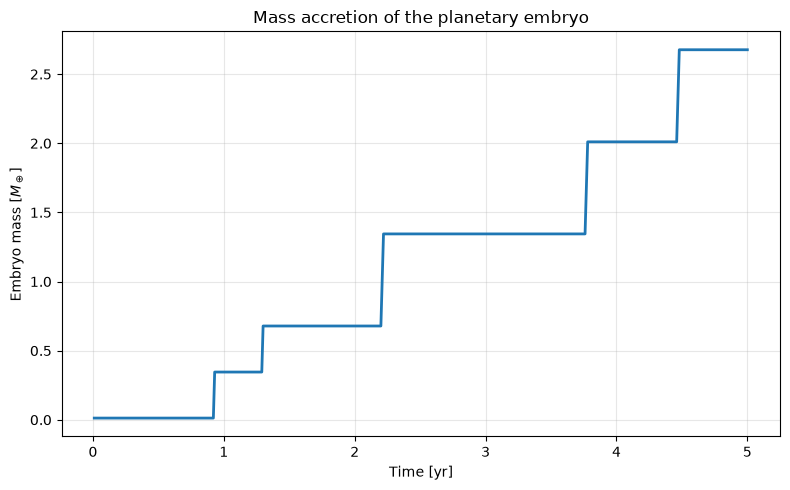

In [22]:
import matplotlib.pyplot as plt



fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(time_saved, mass_embryo, lw=2)

ax.set_xlabel("Time [yr]")
ax.set_ylabel(r"Embryo mass [$M_\oplus$]")
ax.set_title("Mass accretion of the planetary embryo")

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()